In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

from scipy import stats
from scipy.stats import chi2_contingency

import networkx as nx
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

Chargement du dataset

In [5]:
df = pd.read_csv("monitoring_sites.csv")

print("Dimensions du dataset :", df.shape)
print("\nNombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

display(df.head(10))

Dimensions du dataset : (64, 14)

Nombre de lignes : 64
Nombre de colonnes : 14


,site_code,site_name,site_category,region,jurisdiction,latitude,longitude,elevation_m,habitat_category,cave_access_category,orchard_context,programme_start_date,programme_end_date,site_status
0,KNT-KES,Kestrel Cavern Monitoring Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.6800,112.3100,248.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
1,KNT-LUM,Luma Karst Reserve Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.8100,112.4400,25.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
2,KNT-SEN,Senna Ridge Cave Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.5900,112.5000,45.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
3,AVL-MAR,Marula East Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.4100,101.6900,226.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,NaN,active
4,AVL-VEL,Velin Basin Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.5500,101.8400,24.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,NaN,active
5,AVL-ORR,Orra Research Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.6200,101.7200,262.0,research_site,not applicable,commercial or research orchard,2016-01-01,NaN,active
6,TMB-NAC,Nacre Coast Cave Site,cave monitoring,Tembara Coastal Cluster,Tembara Commonwealth,2.1100,104.3600,299.0,coastal_habitat,managed,none recorded,2016-01-01,NaN,active
7,TMB-PEL,Pelagos Grove Monitoring Site,habitat monitoring,Tembara Coastal Cluster,Tembara Commonwealth,2.2700,104.4900,261.0,coastal_habitat,not applicable,none recorded,2016-01-01,NaN,active
8,KNT-CYP,Dune Reach Monitoring Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.8228,112.3675,NaN,karst_habitat,managed,none recorded,2016-01-01,NaN,active
9,KNT-YRX,Garnet Garden Monitoring Site,habitat monitoring,Kintara Karst Cluster,Kintara Republic,4.6832,112.0095,192.3,mixed_forest,not applicable,none recorded,2018-01-01,NaN,active


type de var

In [6]:
print("Informations générales :")
df.info()

print("\nTypes des variables :")
display(df.dtypes.to_frame("Type"))

print("\nNombre de valeurs distinctes :")
display(df.nunique().to_frame("Valeurs uniques"))

Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   site_code             64 non-null     object 
 1   site_name             64 non-null     object 
 2   site_category         64 non-null     object 
 3   region                64 non-null     object 
 4   jurisdiction          64 non-null     object 
 5   latitude              64 non-null     float64
 6   longitude             64 non-null     float64
 7   elevation_m           63 non-null     float64
 8   habitat_category      64 non-null     object 
 9   cave_access_category  64 non-null     object 
 10  orchard_context       64 non-null     object 
 11  programme_start_date  64 non-null     object 
 12  programme_end_date    0 non-null      float64
 13  site_status           64 non-null     object 
dtypes: float64(4), object(10)
memory usage: 7.1+ KB

Ty

,Type
site_code,object
site_name,object
site_category,object
region,object
jurisdiction,object
latitude,float64
longitude,float64
elevation_m,float64
habitat_category,object
cave_access_category,object



Nombre de valeurs distinctes :


,Valeurs uniques
site_code,64
site_name,64
site_category,4
region,3
jurisdiction,3
latitude,64
longitude,64
elevation_m,57
habitat_category,8
cave_access_category,2


STAT

In [7]:
print("Statistiques des variables numériques :")
display(df.describe())

print("\nStatistiques des variables catégorielles :")
display(df.describe(include="object"))

Statistiques des variables numériques :


,latitude,longitude,elevation_m,programme_end_date
count,64.000000,64.000000,63.000000,0.0
mean,4.912042,106.226575,147.852381,NaN
std,2.176913,4.627607,97.097415,NaN
min,1.766800,101.326300,5.000000,NaN
25%,2.414625,101.875900,82.100000,NaN
50%,4.735150,104.455750,142.400000,NaN
75%,7.414150,112.325075,223.300000,NaN
max,7.756800,112.690500,418.800000,NaN



Statistiques des variables catégorielles :


,site_code,site_name,site_category,region,jurisdiction,habitat_category,cave_access_category,orchard_context,programme_start_date,site_status
count,64,64,64,64,64,64,64,64,64,64
unique,64,64,4,3,3,8,2,2,3,1
top,KNT-KES,Kestrel Cavern Monitoring Site,habitat monitoring,Kintara Karst Cluster,Kintara Republic,mixed_forest,not applicable,none recorded,2016-01-01,active
freq,1,1,40,22,22,19,56,48,27,64


Distribution des variables catégorielles


Distribution de site_code :


,Effectif
site_code,
KNT-KES,1
KNT-LUM,1
KNT-SEN,1
AVL-MAR,1
AVL-VEL,1
...,...
TMB-WST,1
TMB-SXP,1
TMB-WQL,1


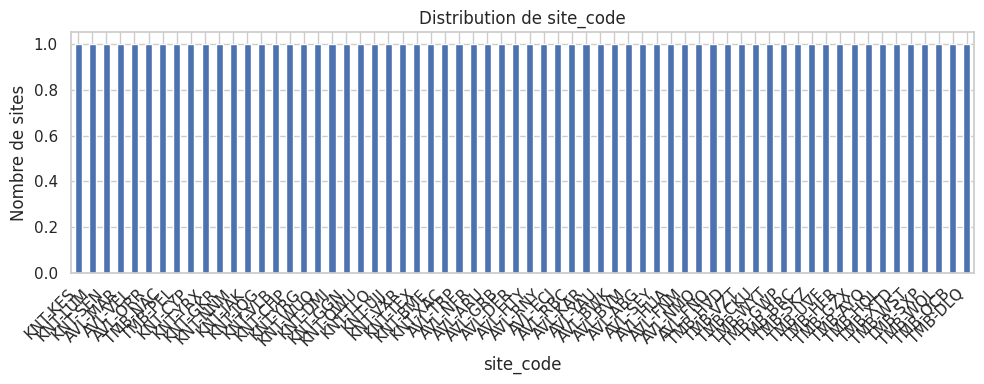


Distribution de site_name :


,Effectif
site_name,
Kestrel Cavern Monitoring Site,1
Luma Karst Reserve Site,1
Senna Ridge Cave Site,1
Marula East Orchard Site,1
Velin Basin Orchard Site,1
...,...
Garnet Valley Monitoring Site,1
Juniper Grove Monitoring Site,1
Mango Coast Monitoring Site,1


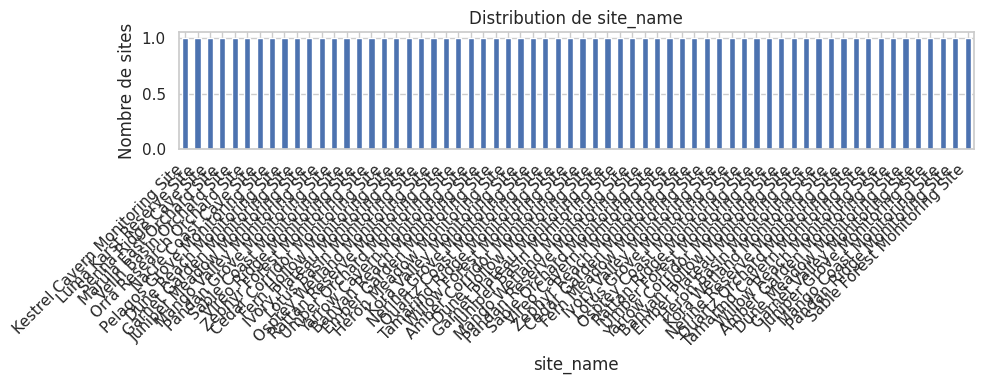


Distribution de site_category :


,Effectif
site_category,
habitat monitoring,40
orchard monitoring,15
cave monitoring,8
ORCHARD MONITORING,1


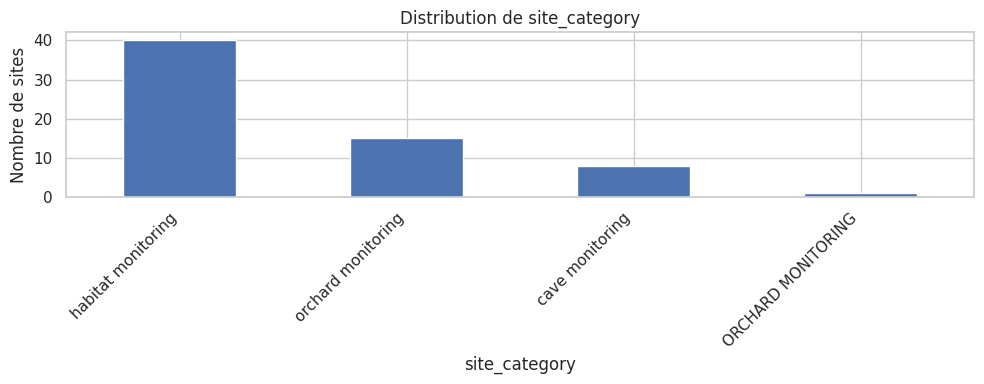


Distribution de region :


,Effectif
region,
Kintara Karst Cluster,22
Eastern Avelora Agricultural Cluster,22
Tembara Coastal Cluster,20


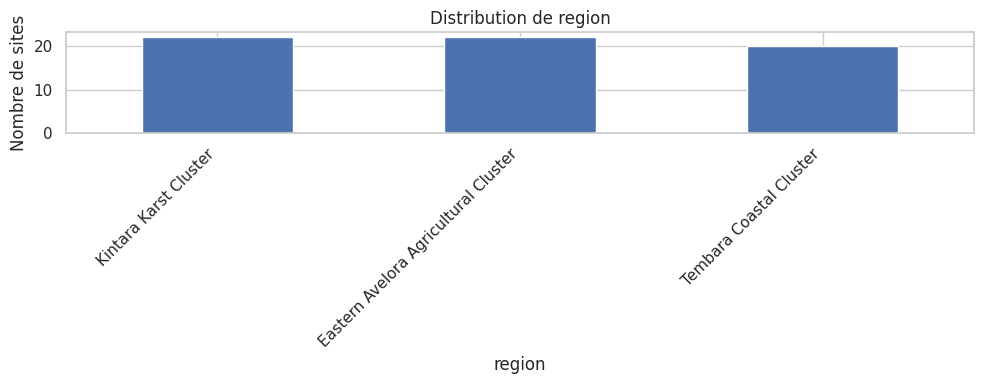


Distribution de jurisdiction :


,Effectif
jurisdiction,
Kintara Republic,22
Avelora Federation,22
Tembara Commonwealth,20


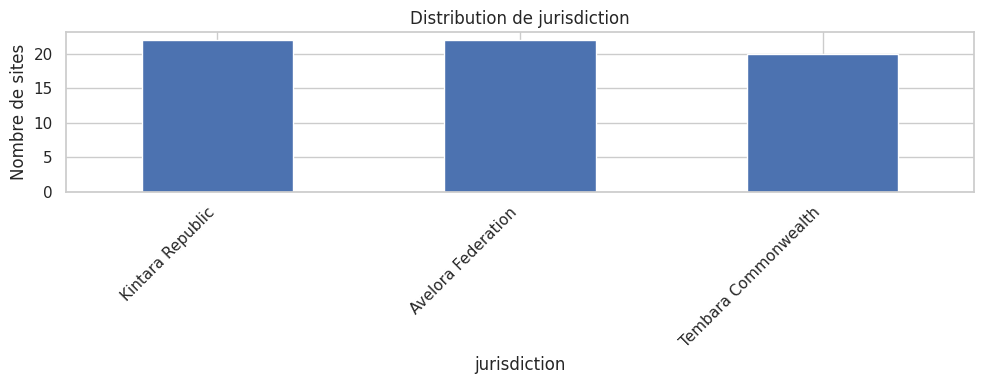


Distribution de habitat_category :


,Effectif
habitat_category,
mixed_forest,19
durian_orchard,10
coastal_habitat,10
karst_habitat,9
research_site,6
mixed_agriculture,5
protected_forest,3
degraded_land,2


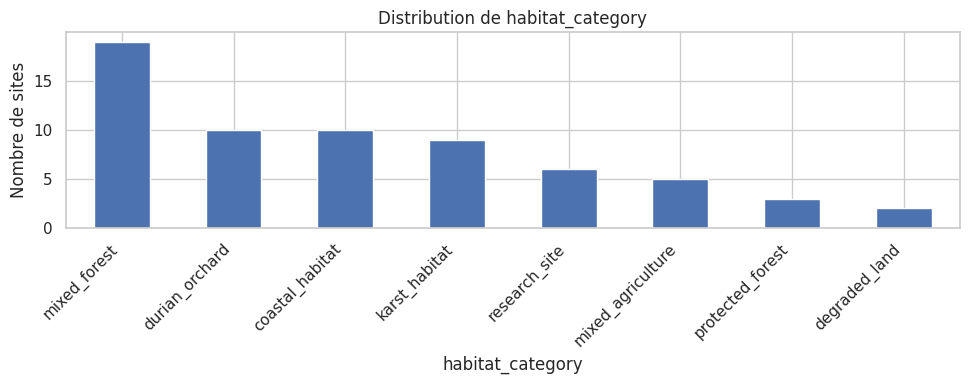


Distribution de cave_access_category :


,Effectif
cave_access_category,
not applicable,56
managed,8


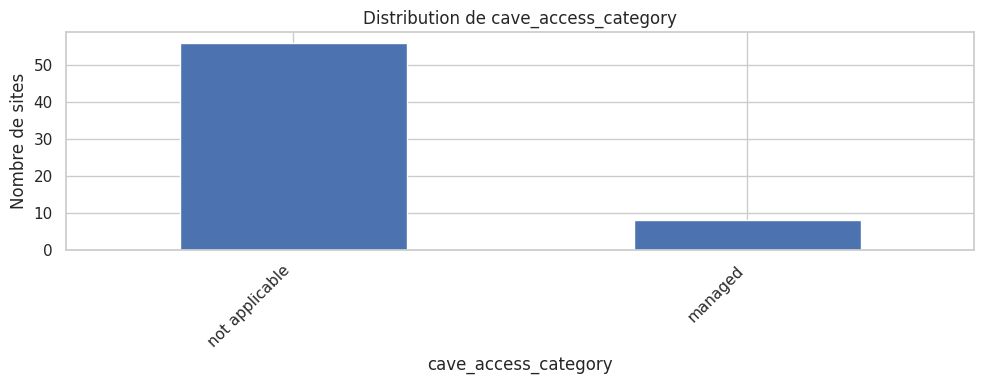


Distribution de orchard_context :


,Effectif
orchard_context,
none recorded,48
commercial or research orchard,16


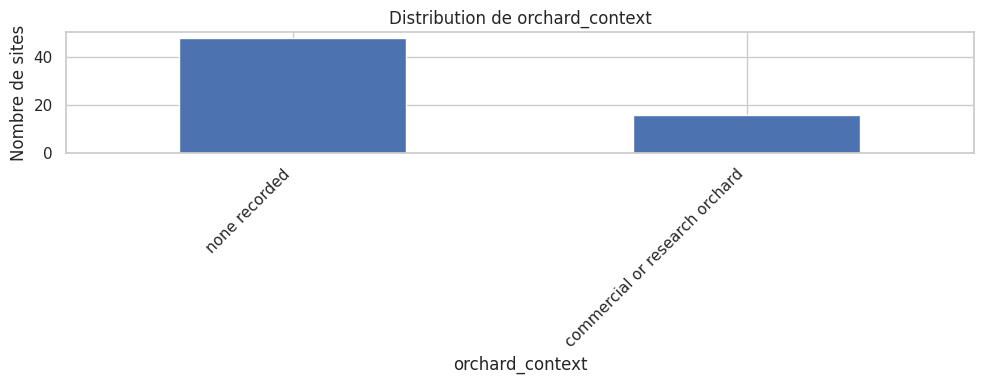


Distribution de programme_start_date :


,Effectif
programme_start_date,
2016-01-01,27
2018-01-01,21
2017-01-01,16


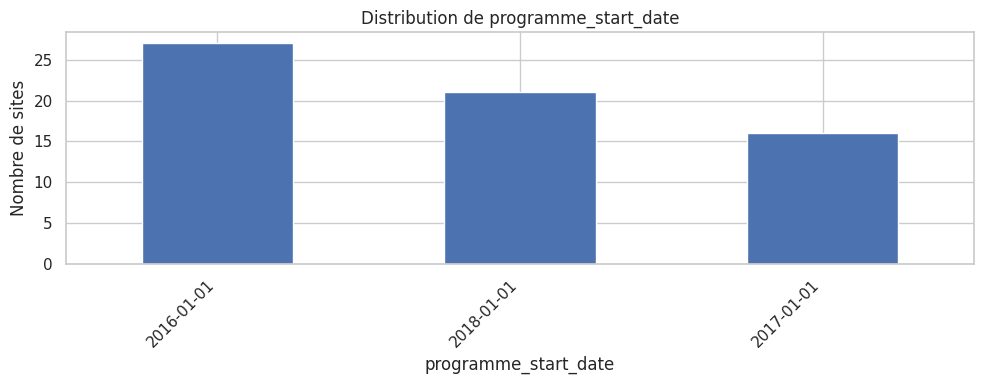


Distribution de site_status :


,Effectif
site_status,
active,64


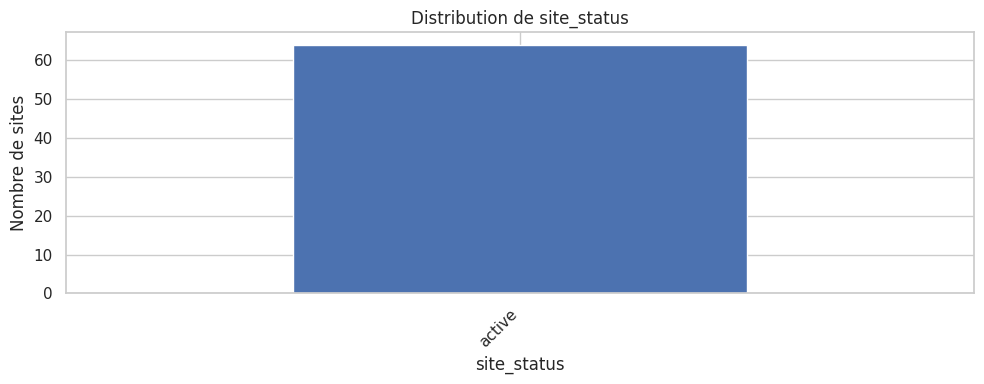

In [8]:
colonnes_cat = df.select_dtypes(include="object").columns

for col in colonnes_cat:
    print(f"\nDistribution de {col} :")
    display(df[col].value_counts(dropna=False).to_frame("Effectif"))

    plt.figure(figsize=(10, 4))
    df[col].value_counts().plot(kind="bar")
    plt.title(f"Distribution de {col}")
    plt.ylabel("Nombre de sites")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

Visualisation des var num

Variables numériques analysées : ['latitude', 'longitude', 'elevation_m']


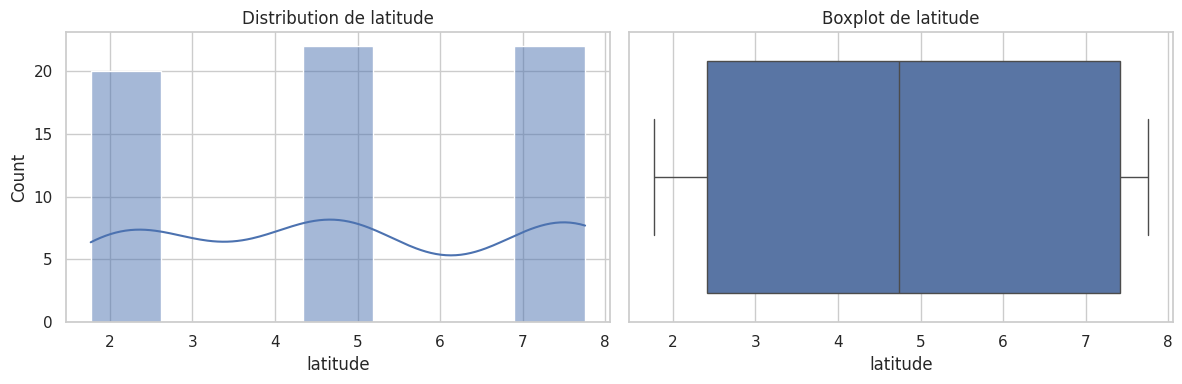

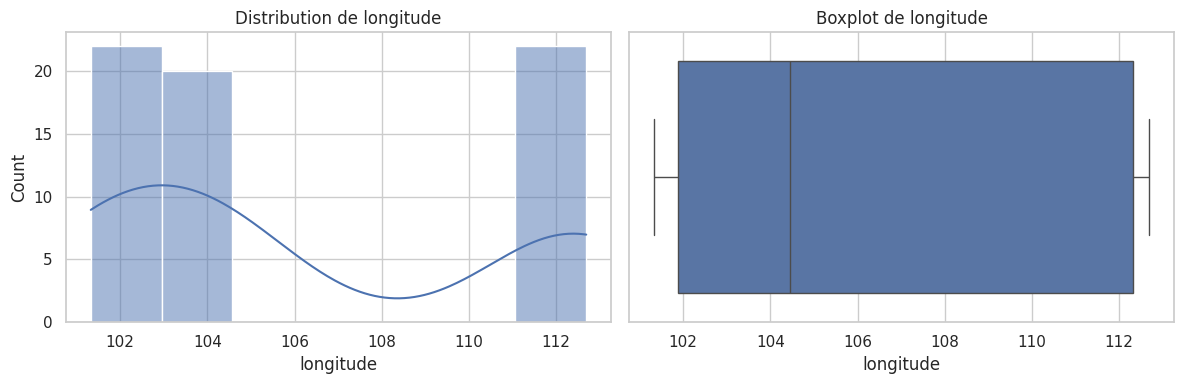

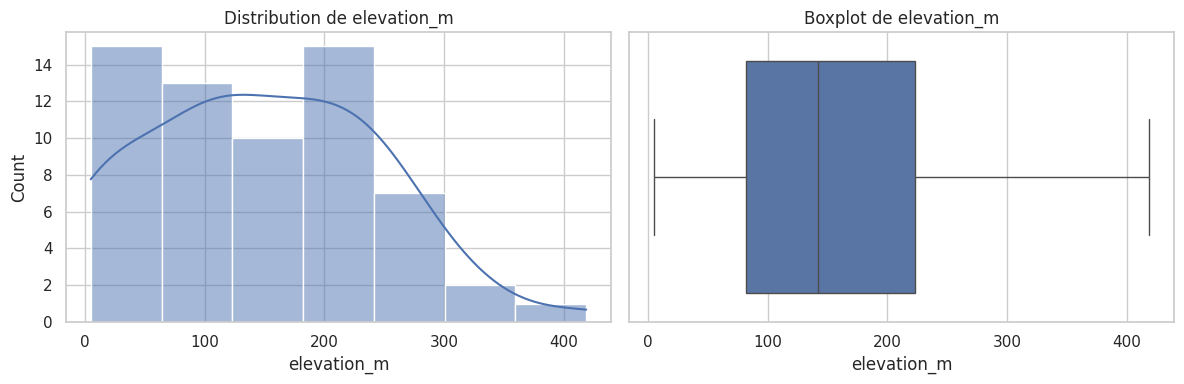

In [11]:
# Sélection des variables numériques
colonnes_num = df.select_dtypes(include=np.number).columns

# Exclusion des colonnes entièrement vides
colonnes_num = [
    col for col in colonnes_num
    if df[col].notna().any()
]

print("Variables numériques analysées :", colonnes_num)

# Visualisation des distributions
for col in colonnes_num:

    valeurs = df[col].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Histogramme
    sns.histplot(valeurs, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution de {col}")

    # Boxplot
    sns.boxplot(x=valeurs, ax=axes[1])
    axes[1].set_title(f"Boxplot de {col}")

    plt.tight_layout()
    plt.show()

Recherche des val manquantes

,Valeurs manquantes,Pourcentage (%)
programme_end_date,64,100.0000
elevation_m,1,1.5625
site_category,0,0.0000
region,0,0.0000
site_code,0,0.0000
site_name,0,0.0000
latitude,0,0.0000
jurisdiction,0,0.0000
habitat_category,0,0.0000
longitude,0,0.0000


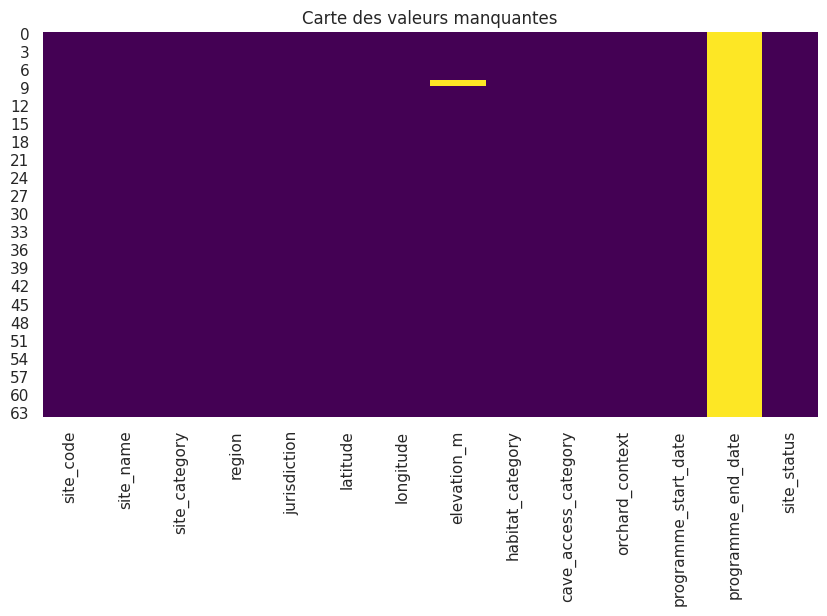

In [12]:
missing = pd.DataFrame({
    "Valeurs manquantes": df.isnull().sum(),
    "Pourcentage (%)": df.isnull().mean() * 100
})

missing = missing.sort_values(
    by="Pourcentage (%)",
    ascending=False
)

display(missing)

plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Carte des valeurs manquantes")
plt.show()

doublons

In [13]:
print("Nombre de doublons complets :", df.duplicated().sum())

print("Nombre de codes de sites dupliqués :",
      df["site_code"].duplicated().sum())

print("\nLignes ayant un code dupliqué :")

display(
    df[df["site_code"].duplicated(keep=False)]
)

Nombre de doublons complets : 0
Nombre de codes de sites dupliqués : 0

Lignes ayant un code dupliqué :


,site_code,site_name,site_category,region,jurisdiction,latitude,longitude,elevation_m,habitat_category,cave_access_category,orchard_context,programme_start_date,programme_end_date,site_status


Vérification des incohérences

In [14]:
print("Valeurs distinctes des catégories :")

for col in ["site_category", "region",
            "habitat_category", "site_status"]:
    print(f"\n{col} :")
    print(df[col].unique())

print("\nVérification des coordonnées :")

print("Latitude hors limites :",
      ((df["latitude"] < -90) |
       (df["latitude"] > 90)).sum())

print("Longitude hors limites :",
      ((df["longitude"] < -180) |
       (df["longitude"] > 180)).sum())

print("\nDates de début :")
print(df["programme_start_date"].value_counts())

print("\nDates de fin :")
print(df["programme_end_date"].value_counts(dropna=False))

Valeurs distinctes des catégories :

site_category :
['cave monitoring' 'orchard monitoring' 'habitat monitoring'
 'ORCHARD MONITORING']

region :
['Kintara Karst Cluster' 'Eastern Avelora Agricultural Cluster'
 'Tembara Coastal Cluster']

habitat_category :
['karst_habitat' 'durian_orchard' 'research_site' 'coastal_habitat'
 'mixed_forest' 'protected_forest' 'degraded_land' 'mixed_agriculture']

site_status :
['active']

Vérification des coordonnées :
Latitude hors limites : 0
Longitude hors limites : 0

Dates de début :
programme_start_date
2016-01-01    27
2018-01-01    21
2017-01-01    16
Name: count, dtype: int64

Dates de fin :
programme_end_date
NaN    64
Name: count, dtype: int64


nettoyage

In [15]:
sites = df.copy()

# Normalisation des espaces et de la casse
colonnes_texte = [
    "site_category",
    "region",
    "jurisdiction",
    "habitat_category",
    "cave_access_category",
    "orchard_context",
    "site_status"
]

for col in colonnes_texte:
    sites[col] = sites[col].astype("string").str.strip().str.lower()

# Conversion des dates
sites["programme_start_date"] = pd.to_datetime(
    sites["programme_start_date"],
    errors="coerce"
)

sites["programme_end_date"] = pd.to_datetime(
    sites["programme_end_date"],
    errors="coerce"
)


sites = sites.drop_duplicates(subset="site_code")

# Conservation d'un indicateur pour l'altitude manquante
sites["elevation_missing"] = sites["elevation_m"].isna()

# Imputation par la médiane de la région
sites["elevation_m"] = sites.groupby("region")[
    "elevation_m"
].transform(lambda x: x.fillna(x.median()))

print("Dimensions après nettoyage :", sites.shape)

print("\nValeurs manquantes restantes :")
display(sites.isnull().sum().to_frame("Valeurs manquantes"))

Dimensions après nettoyage : (64, 15)

Valeurs manquantes restantes :


,Valeurs manquantes
site_code,0
site_name,0
site_category,0
region,0
jurisdiction,0
latitude,0
longitude,0
elevation_m,0
habitat_category,0
cave_access_category,0


On conserve programme_end_date car son absence peut signifier que les programmes sont toujours en cours.



On conserve site_status même s'il est constant.



On remplace uniquement l'altitude manquante par la médiane de sa région.



On conserve une colonne indiquant que cette altitude était initialement manquante

Analyse statistique et corrélations

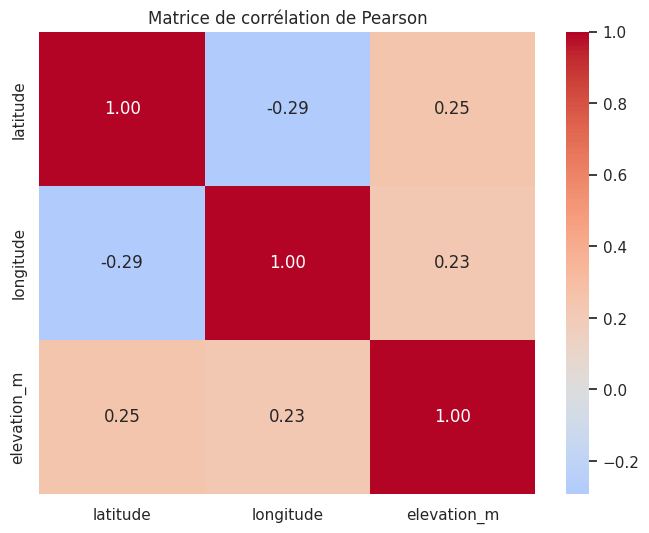

In [16]:
variables_num = [
    "latitude",
    "longitude",
    "elevation_m"
]

corr = sites[variables_num].corr(method="pearson")

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Matrice de corrélation de Pearson")
plt.show()

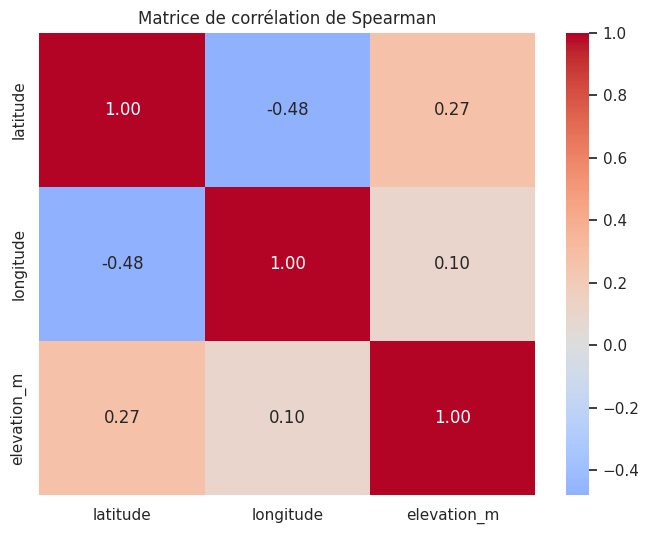

In [17]:
corr_spearman = sites[variables_num].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_spearman,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Matrice de corrélation de Spearman")
plt.show()

Analyse des relations entre variables catégorielles

In [18]:
relations = [
    ("region", "site_category"),
    ("region", "habitat_category"),
    ("region", "orchard_context"),
    ("site_category", "habitat_category")
]

for col1, col2 in relations:

    tableau = pd.crosstab(
        sites[col1],
        sites[col2]
    )

    print(f"\nRelation entre {col1} et {col2}")
    display(tableau)

    if tableau.shape[0] > 1 and tableau.shape[1] > 1:
        chi2, p, ddl, expected = chi2_contingency(tableau)

        print("Chi-deux :", round(chi2, 3))
        print("P-value :", round(p, 4))
        print("Degrés de liberté :", ddl)

        if p < 0.05:
            print("Association statistiquement significative.")
        else:
            print("Association non significative.")


Relation entre region et site_category


site_category,cave monitoring,habitat monitoring,orchard monitoring
region,,,
eastern avelora agricultural cluster,0,9,13
kintara karst cluster,7,15,0
tembara coastal cluster,1,16,3


Chi-deux : 29.48
P-value : 0.0
Degrés de liberté : 4
Association statistiquement significative.

Relation entre region et habitat_category


habitat_category,coastal_habitat,degraded_land,durian_orchard,karst_habitat,mixed_agriculture,mixed_forest,protected_forest,research_site
region,,,,,,,,
eastern avelora agricultural cluster,0,0,7,0,5,4,0,6
kintara karst cluster,0,2,0,9,0,8,3,0
tembara coastal cluster,10,0,3,0,0,7,0,0


Chi-deux : 78.363
P-value : 0.0
Degrés de liberté : 14
Association statistiquement significative.

Relation entre region et orchard_context


orchard_context,commercial or research orchard,none recorded
region,,
eastern avelora agricultural cluster,13,9
kintara karst cluster,0,22
tembara coastal cluster,3,17


Chi-deux : 22.036
P-value : 0.0
Degrés de liberté : 2
Association statistiquement significative.

Relation entre site_category et habitat_category


habitat_category,coastal_habitat,degraded_land,durian_orchard,karst_habitat,mixed_agriculture,mixed_forest,protected_forest,research_site
site_category,,,,,,,,
cave monitoring,1,0,0,7,0,0,0,0
habitat monitoring,9,2,0,2,0,19,3,5
orchard monitoring,0,0,10,0,5,0,0,1


Chi-deux : 99.76
P-value : 0.0
Degrés de liberté : 14
Association statistiquement significative.


Analyse géographique et visualisation spatiale

Répartition géographique des sites

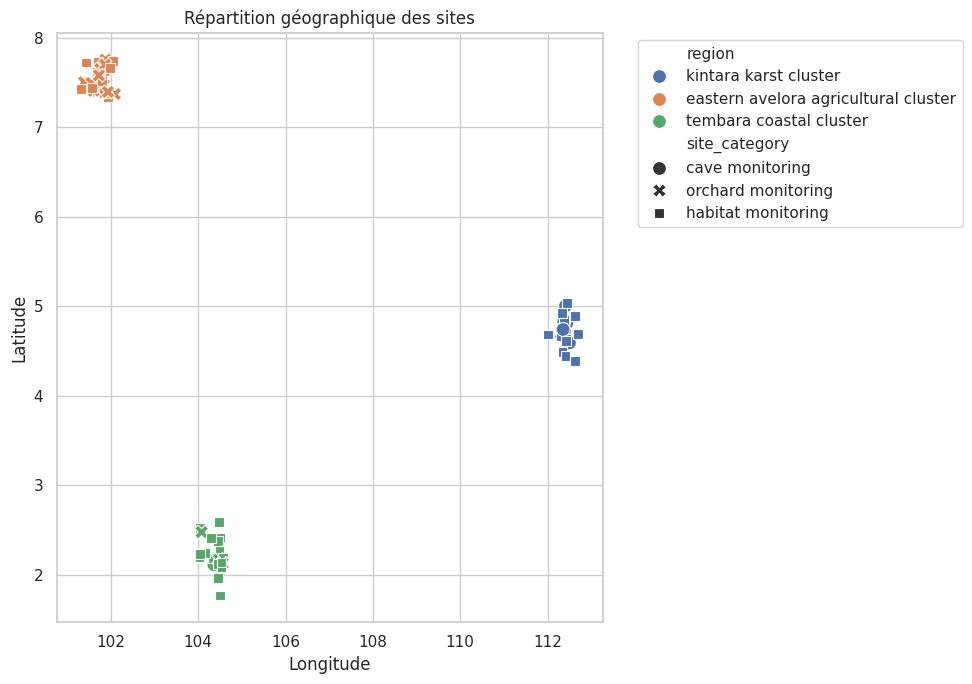

In [19]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=sites,
    x="longitude",
    y="latitude",
    hue="region",
    style="site_category",
    s=100
)

plt.title("Répartition géographique des sites")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

Analyse de l'altitude par région

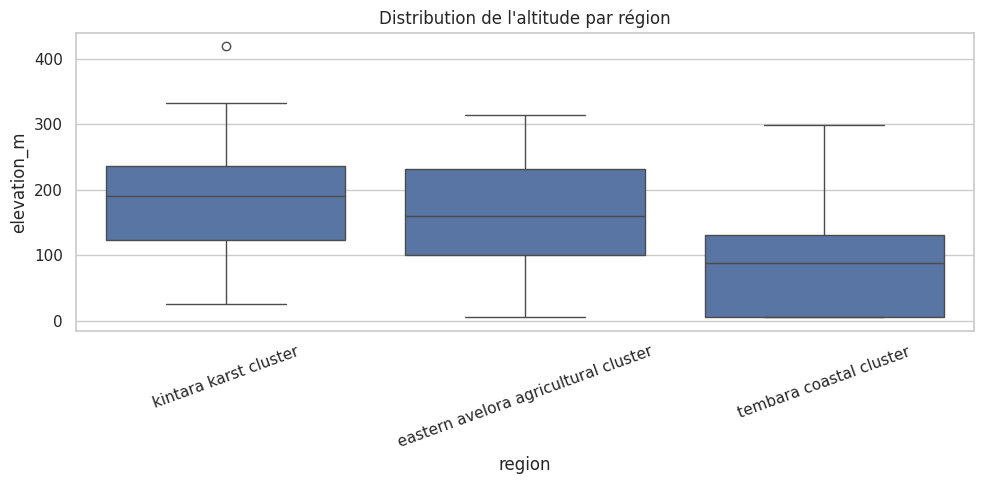

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=sites,
    x="region",
    y="elevation_m"
)

plt.title("Distribution de l'altitude par région")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Répartition des catégories par région

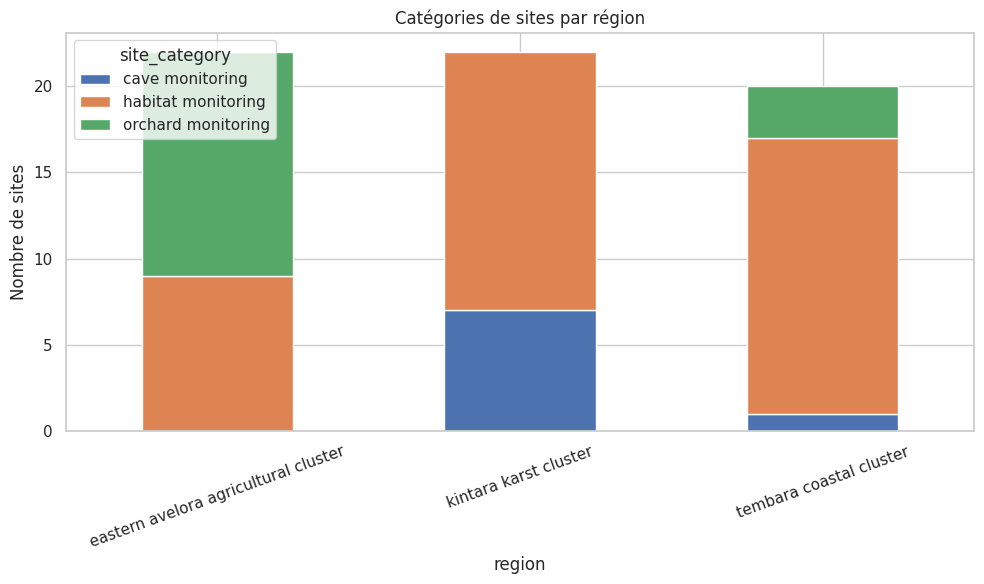

In [21]:
table_region = pd.crosstab(
    sites["region"],
    sites["site_category"]
)

table_region.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Catégories de sites par région")
plt.ylabel("Nombre de sites")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Clustering

In [22]:
X_geo = sites[
    ["latitude", "longitude", "elevation_m"]
].copy()

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_geo)

print("Dimensions de la matrice :", X_scaled.shape)

Dimensions de la matrice : (64, 3)


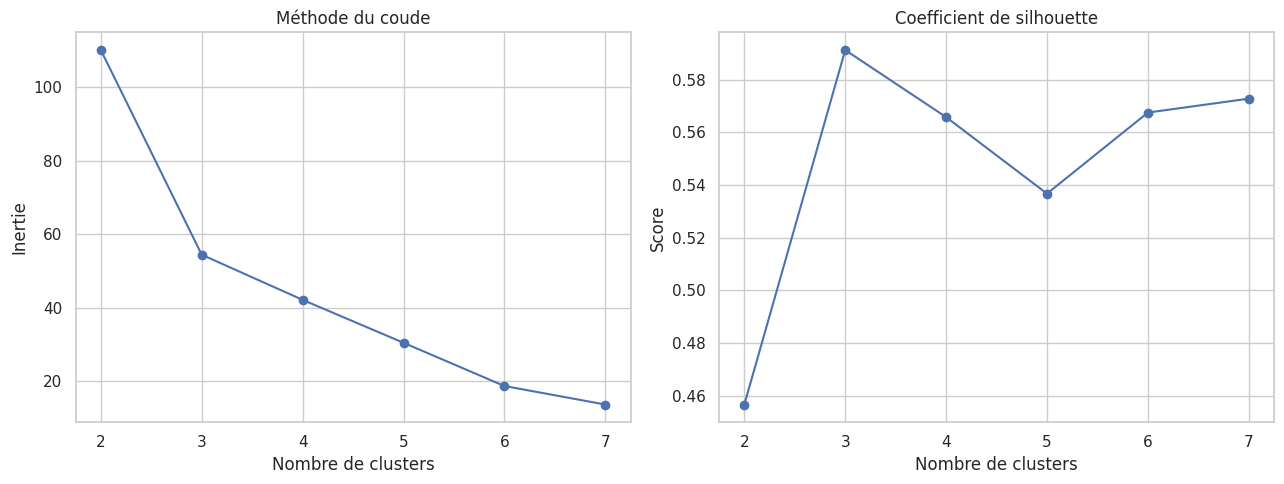

In [23]:
inerties = []
silhouettes = []

valeurs_k = range(2, 8)

for k in valeurs_k:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inerties.append(model.inertia_)

    silhouettes.append(
        silhouette_score(X_scaled, labels)
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(valeurs_k, inerties, marker="o")
axes[0].set_title("Méthode du coude")
axes[0].set_xlabel("Nombre de clusters")
axes[0].set_ylabel("Inertie")

axes[1].plot(valeurs_k, silhouettes, marker="o")
axes[1].set_title("Coefficient de silhouette")
axes[1].set_xlabel("Nombre de clusters")
axes[1].set_ylabel("Score")

plt.tight_layout()
plt.show()

Kmeans

In [24]:
k_optimal = 3  # À ajuster selon les résultats précédents

kmeans = KMeans(
    n_clusters=k_optimal,
    random_state=42,
    n_init=10
)

sites["geo_cluster"] = kmeans.fit_predict(X_scaled)

print("Répartition des clusters :")
display(sites["geo_cluster"].value_counts().sort_index())

print("\nCaractéristiques des clusters :")

display(
    sites.groupby("geo_cluster")[
        ["latitude", "longitude", "elevation_m"]
    ].mean()
)

Répartition des clusters :


,count
geo_cluster,
0,22
1,20
2,22



Caractéristiques des clusters :


,latitude,longitude,elevation_m
geo_cluster,,,
0,4.723509,112.394241,187.209091
1,2.228070,104.367910,95.235000
2,7.540550,101.748605,158.263636


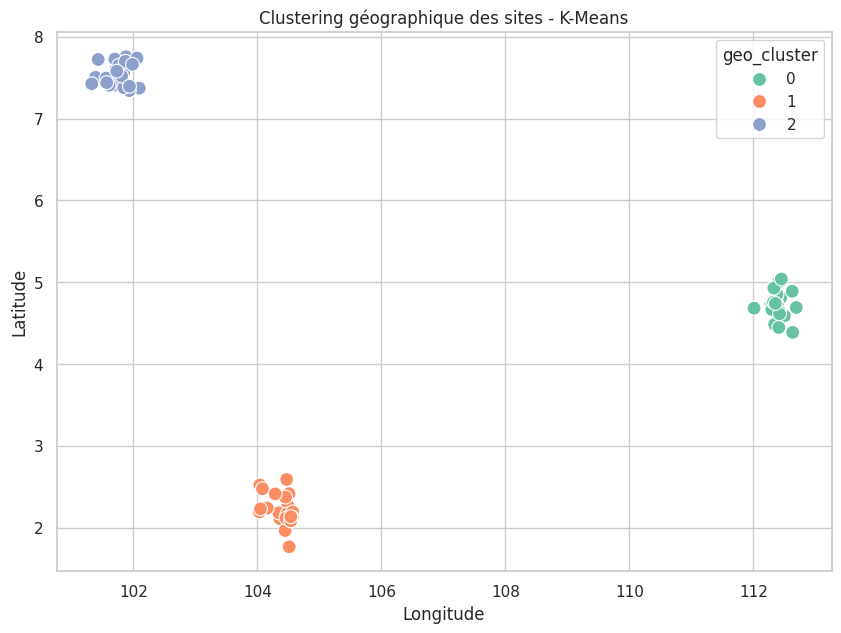

In [25]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=sites,
    x="longitude",
    y="latitude",
    hue="geo_cluster",
    palette="Set2",
    s=100
)

plt.title("Clustering géographique des sites - K-Means")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

DBSCAN

Répartition DBSCAN :


,count
dbscan_cluster,
1,22
0,21
2,20
-1,1


Nombre de points considérés comme bruit : 1


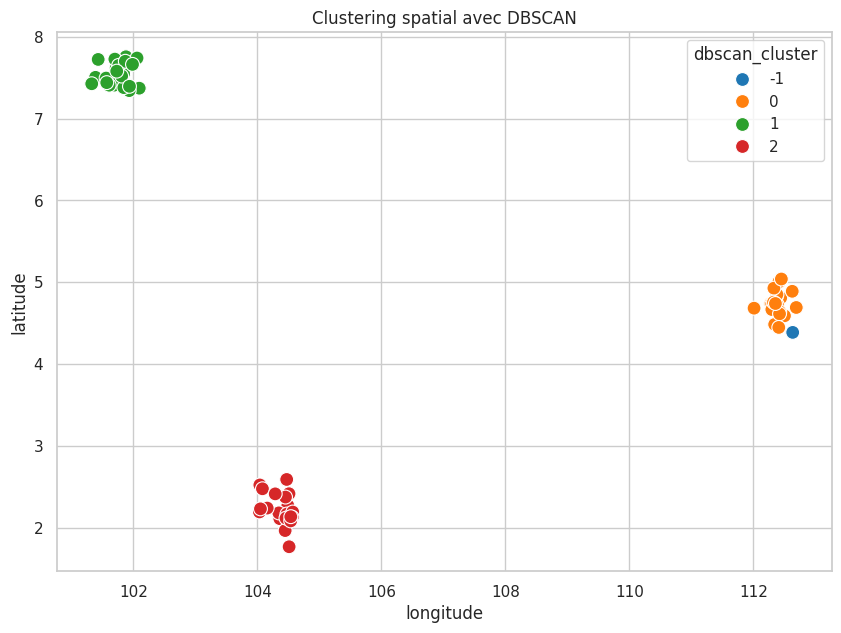

In [26]:
dbscan = DBSCAN(
    eps=0.8,
    min_samples=3
)

sites["dbscan_cluster"] = dbscan.fit_predict(X_scaled)

print("Répartition DBSCAN :")
display(sites["dbscan_cluster"].value_counts())

print(
    "Nombre de points considérés comme bruit :",
    (sites["dbscan_cluster"] == -1).sum()
)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=sites,
    x="longitude",
    y="latitude",
    hue="dbscan_cluster",
    palette="tab10",
    s=100
)

plt.title("Clustering spatial avec DBSCAN")
plt.show()

Détection des anomalies

isolation forest

In [27]:
iso = IsolationForest(
    contamination=0.05,
    random_state=42
)

sites["anomaly_if"] = iso.fit_predict(X_scaled)

sites["anomaly_if"] = sites["anomaly_if"].map({
    1: "Normal",
    -1: "Anomalie"
})

print("Résultats Isolation Forest :")

display(
    sites["anomaly_if"].value_counts()
)

print("\nSites identifiés comme anomalies :")

display(
    sites[sites["anomaly_if"] == "Anomalie"][
        ["site_code", "site_name", "region",
         "latitude", "longitude", "elevation_m"]
    ]
)

Résultats Isolation Forest :


,count
anomaly_if,
Normal,60
Anomalie,4



Sites identifiés comme anomalies :


,site_code,site_name,region,latitude,longitude,elevation_m
6,TMB-NAC,Nacre Coast Cave Site,tembara coastal cluster,2.1100,104.3600,299.0
15,KNT-CHP,Zephyr Forest Monitoring Site,kintara karst cluster,4.3872,112.6329,418.8
23,KNT-VXR,Yarrow Cavern Monitoring Site,kintara karst cluster,4.4479,112.4086,332.8
29,AVL-ARU,Quartz Coast Monitoring Site,eastern avelora agricultural cluster,7.7240,101.4303,314.3


Local Outlier Factor

In [28]:
lof = LocalOutlierFactor(
    n_neighbors=10,
    contamination=0.05
)

lof_labels = lof.fit_predict(X_scaled)

sites["anomaly_lof"] = np.where(
    lof_labels == -1,
    "Anomalie",
    "Normal"
)

print("Résultats LOF :")

display(sites["anomaly_lof"].value_counts())

print("\nComparaison des deux méthodes :")

display(
    pd.crosstab(
        sites["anomaly_if"],
        sites["anomaly_lof"]
    )
)

Résultats LOF :


,count
anomaly_lof,
Normal,60
Anomalie,4



Comparaison des deux méthodes :


anomaly_lof,Anomalie,Normal
anomaly_if,,
Anomalie,3,1
Normal,1,59


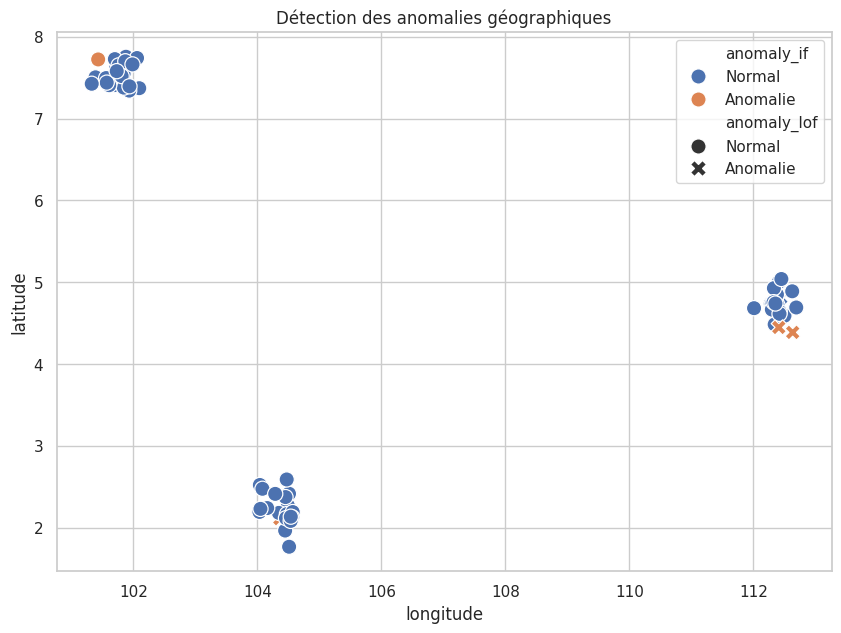

In [29]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=sites,
    x="longitude",
    y="latitude",
    hue="anomaly_if",
    style="anomaly_lof",
    s=120
)

plt.title("Détection des anomalies géographiques")
plt.show()

Graph Mining

Comme le CSV ne contient pas directement de relations entre sites, nous allons construire un graphe à partir de leur proximité géographique.

In [30]:
from math import radians, sin, cos, asin, sqrt

def distance_km(lat1, lon1, lat2, lon2):

    lat1, lon1, lat2, lon2 = map(
        radians,
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2)**2
        + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    )

    return 6371 * 2 * asin(sqrt(a))


G = nx.Graph()

# Création des nœuds
for _, row in sites.iterrows():

    G.add_node(
        row["site_code"],
        name=row["site_name"],
        region=row["region"],
        category=row["site_category"]
    )

# Création des relations géographiques
for region, groupe in sites.groupby("region"):

    indices = groupe.index.tolist()

    for i in indices:

        distances = []

        for j in indices:

            if i == j:
                continue

            d = distance_km(
                sites.loc[i, "latitude"],
                sites.loc[i, "longitude"],
                sites.loc[j, "latitude"],
                sites.loc[j, "longitude"]
            )

            distances.append((j, d))

        voisins = sorted(
            distances,
            key=lambda x: x[1]
        )[:3]

        for j, d in voisins:

            code1 = sites.loc[i, "site_code"]
            code2 = sites.loc[j, "site_code"]

            G.add_edge(
                code1,
                code2,
                distance_km=d
            )

print("Nombre de nœuds :", G.number_of_nodes())
print("Nombre de relations :", G.number_of_edges())
print("Nombre de composantes connexes :",
      nx.number_connected_components(G))

Nombre de nœuds : 64
Nombre de relations : 130
Nombre de composantes connexes : 3


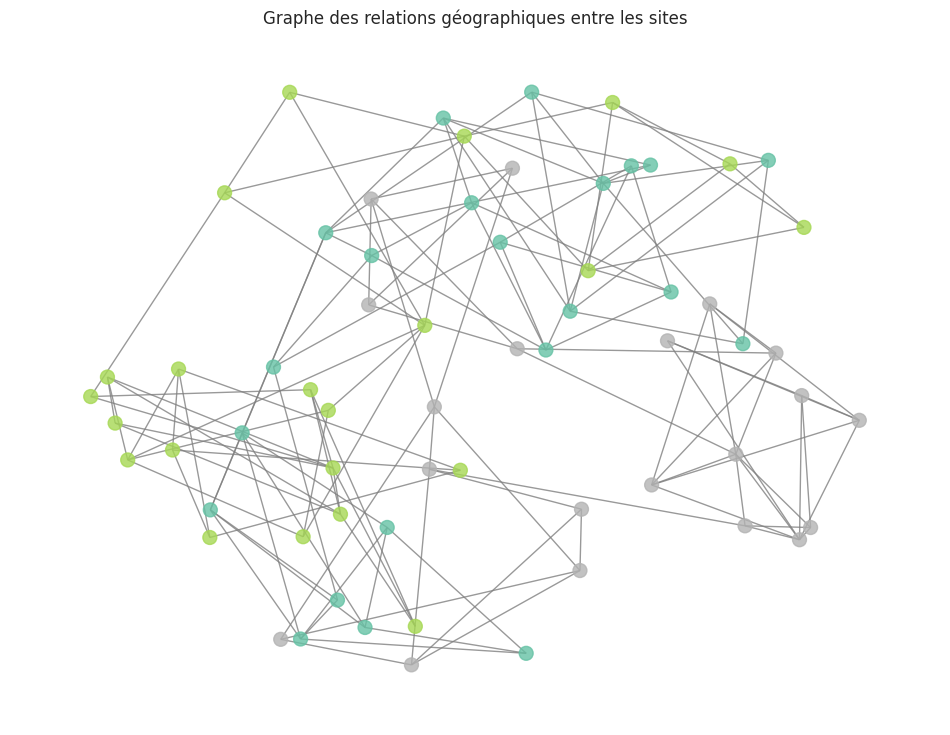

In [31]:
plt.figure(figsize=(12, 9))

pos = nx.spring_layout(
    G,
    seed=42,
    k=0.8
)

couleurs = [
    G.nodes[node]["region"]
    for node in G.nodes()
]

nx.draw_networkx(
    G,
    pos,
    with_labels=False,
    node_size=100,
    node_color=pd.factorize(couleurs)[0],
    cmap=plt.cm.Set2,
    edge_color="gray",
    alpha=0.8
)

plt.title("Graphe des relations géographiques entre les sites")
plt.axis("off")
plt.show()

In [32]:
degree = nx.degree_centrality(G)

betweenness = nx.betweenness_centrality(
    G,
    weight="distance_km"
)

centrality = pd.DataFrame({
    "site_code": list(G.nodes()),
    "degree_centrality": [
        degree[n] for n in G.nodes()
    ],
    "betweenness_centrality": [
        betweenness[n] for n in G.nodes()
    ]
})

centrality = centrality.merge(
    sites[["site_code", "site_name", "region"]],
    on="site_code"
)

display(
    centrality.sort_values(
        "degree_centrality",
        ascending=False
    ).head(10)
)

,site_code,degree_centrality,betweenness_centrality,site_name,region
51,TMB-BRC,0.111111,0.028162,Heron Basin Monitoring Site,tembara coastal cluster
58,TMB-XTD,0.111111,0.009729,Dune Meadow Monitoring Site,tembara coastal cluster
11,KNT-NNM,0.095238,0.048643,Mango Valley Monitoring Site,kintara karst cluster
16,KNT-YRG,0.095238,0.016385,Cedar Corridor Monitoring Site,kintara karst cluster
44,AVL-NMQ,0.095238,0.044035,Lotus Grove Monitoring Site,eastern avelora agricultural cluster
35,AVL-RBC,0.095238,0.004096,Juniper Basin Monitoring Site,eastern avelora agricultural cluster
10,KNT-GKR,0.079365,0.004096,Juniper Meadow Monitoring Site,kintara karst cluster
2,KNT-SEN,0.079365,0.009729,Senna Ridge Cave Site,kintara karst cluster
28,AVL-NFR,0.079365,0.061956,Nerine Grove Monitoring Site,eastern avelora agricultural cluster
38,AVL-BWK,0.079365,0.013825,Sable Orchard Monitoring Site,eastern avelora agricultural cluster


Mining Text and Other Unstructured Data

,Mot,Fréquence
45,site,64
28,monitoring,58
31,orchard,6
42,ridge,5
6,coast,5
15,grove,5
4,cavern,4
48,valley,4
27,meadow,4
41,reserve,4


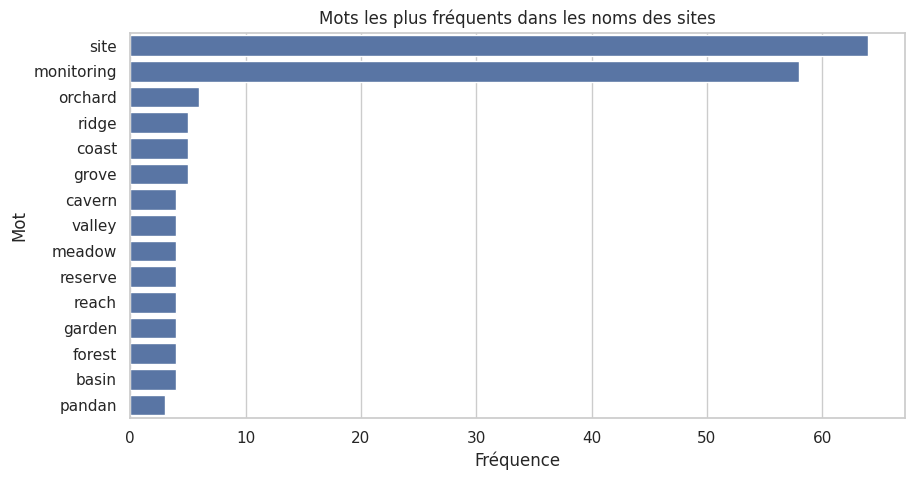

In [33]:
from sklearn.feature_extraction.text import CountVectorizer

textes = sites["site_name"].fillna("")

vectorizer = CountVectorizer(
    stop_words="english"
)

X_text = vectorizer.fit_transform(textes)

frequences = pd.DataFrame({
    "Mot": vectorizer.get_feature_names_out(),
    "Fréquence": np.asarray(
        X_text.sum(axis=0)
    ).ravel()
})

frequences = frequences.sort_values(
    "Fréquence",
    ascending=False
)

display(frequences.head(20))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=frequences.head(15),
    x="Fréquence",
    y="Mot"
)

plt.title("Mots les plus fréquents dans les noms des sites")
plt.show()

Mining Spatial and Temporal Data

On examine les dates de lancement des programmes.

Répartition des sites par année :


,count
start_year,
2016,27
2017,16
2018,21


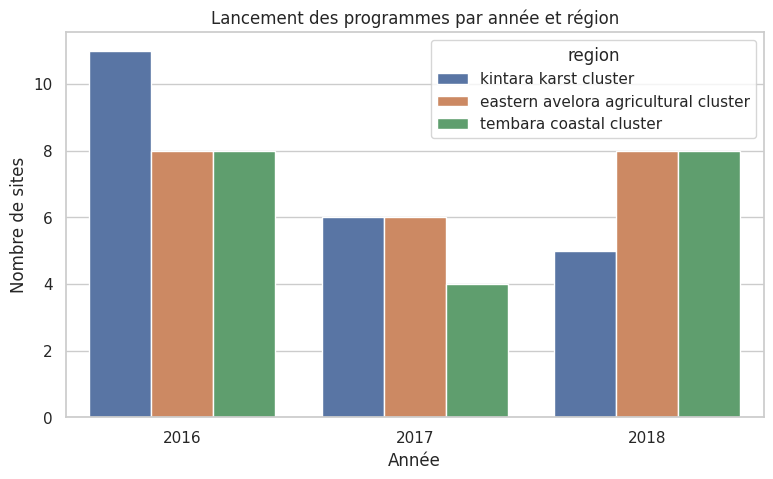

In [34]:
sites["start_year"] = (
    sites["programme_start_date"].dt.year
)

print("Répartition des sites par année :")

display(
    sites["start_year"].value_counts().sort_index()
)

plt.figure(figsize=(9, 5))

sns.countplot(
    data=sites,
    x="start_year",
    hue="region"
)

plt.title("Lancement des programmes par année et région")
plt.xlabel("Année")
plt.ylabel("Nombre de sites")
plt.show()

Comparaison temporelle entre régions

region,eastern avelora agricultural cluster,kintara karst cluster,tembara coastal cluster
start_year,,,
2016,8,11,8
2017,6,6,4
2018,8,5,8


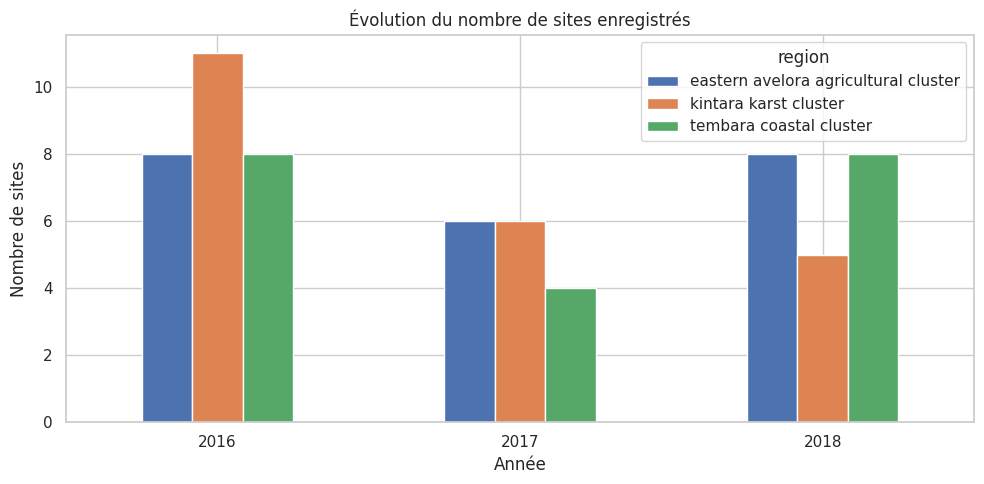

In [35]:
table_temps = pd.crosstab(
    sites["start_year"],
    sites["region"]
)

display(table_temps)

table_temps.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Évolution du nombre de sites enregistrés")
plt.xlabel("Année")
plt.ylabel("Nombre de sites")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [36]:
print("========== SYNTHÈSE DU DATASET ==========")

print("\n1. Nombre de sites :", len(sites))

print("\n2. Répartition par région :")
display(sites["region"].value_counts())

print("\n3. Répartition par catégorie :")
display(sites["site_category"].value_counts())

print("\n4. Répartition par habitat :")
display(sites["habitat_category"].value_counts())

print("\n5. Répartition des clusters :")
display(sites["geo_cluster"].value_counts())

print("\n6. Anomalies Isolation Forest :")
display(sites["anomaly_if"].value_counts())

print("\n7. Anomalies LOF :")
display(sites["anomaly_lof"].value_counts())

print("\n8. Sites avec altitude initialement manquante :")
display(
    sites[sites["elevation_missing"]][
        ["site_code", "region", "elevation_m"]
    ]
)

========== SYNTHÈSE DU DATASET ==========

1. Nombre de sites : 64

2. Répartition par région :


,count
region,
kintara karst cluster,22
eastern avelora agricultural cluster,22
tembara coastal cluster,20



3. Répartition par catégorie :


,count
site_category,
habitat monitoring,40
orchard monitoring,16
cave monitoring,8



4. Répartition par habitat :


,count
habitat_category,
mixed_forest,19
durian_orchard,10
coastal_habitat,10
karst_habitat,9
research_site,6
mixed_agriculture,5
protected_forest,3
degraded_land,2


... (4 outputs left out)


7. Anomalies LOF :


,count
anomaly_lof,
Normal,60
Anomalie,4



8. Sites avec altitude initialement manquante :


,site_code,region,elevation_m
8,KNT-CYP,kintara karst cluster,190.4


In [37]:
sites.to_csv(
    "monitoring_sites_analyzed.csv",
    index=False
)

centrality.to_csv(
    "monitoring_sites_graph_metrics.csv",
    index=False
)

print("Les résultats ont été sauvegardés.")

Les résultats ont été sauvegardés.


1. Structure générale du dataset
Le dataset contient 64 sites répartis dans trois régions géographiques : Kintara (22 sites), Avelora (22 sites) et Tembara (20 sites). La répartition est relativement équilibrée entre les régions.

Les sites sont répartis en trois catégories :
- Habitat monitoring : 40 sites (62,5 %).
- Orchard monitoring : 16 sites (25 %).
- Cave monitoring : 8 sites (12,5 %).
La catégorie habitat monitoring est donc largement majoritaire. Concernant les habitats, les forêts mixtes sont les plus représentées (19 sites), suivies des vergers de durian et des habitats côtiers (10 sites chacun).
2. Qualité et nettoyage des données
L'analyse de la qualité des données a révélé une seule valeur manquante dans elevation_m, concernant le site KNT-CYP. Cette valeur a été remplacée par la médiane des altitudes de sa région, soit 190,4 mètres. Une variable supplémentaire a été conservée pour identifier cette valeur initialement manquante.

Par ailleurs, la colonne programme_end_date est entièrement vide, tandis que site_status contient uniquement la valeur active. Ces variables n'apportent donc pas de distinction entre les sites dans leur état actuel. Il convient néanmoins de les conserver pour ne pas perdre d'informations sur la structure initiale du dataset.
3. Analyse géographique et clustering
La visualisation des coordonnées permet d'observer une répartition géographique des sites en trois ensembles correspondant aux régions étudiées.

Le clustering K-Means, réalisé avec trois groupes à partir de la latitude, de la longitude et de l'altitude, retrouve exactement cette séparation :
- Cluster 0 : 22 sites de Kintara.
- Cluster 1 : 20 sites de Tembara.
- Cluster 2 : 22 sites d'Avelora.
Ce résultat montre que les caractéristiques géographiques permettent de distinguer clairement les trois ensembles régionaux dans ce dataset.

Le résultat est intéressant car il confirme la structuration spatiale des données. Toutefois, il ne démontre pas à lui seul l'existence de différences écologiques entre les régions.
4. Détection des anomalies
Les deux méthodes utilisées, Isolation Forest et Local Outlier Factor (LOF), ont chacune identifié quatre sites comme anomalies.

Trois sites sont identifiés par les deux méthodes, tandis qu'un site supplémentaire diffère selon l'algorithme. Cela montre que les deux approches détectent globalement des observations similaires, mais ne produisent pas exactement les mêmes résultats.

Ces sites présentent des caractéristiques géographiques particulières, notamment des altitudes relativement élevées ou des positions géographiques atypiques par rapport aux autres observations.

Ces anomalies doivent être considérées comme des observations à examiner davantage et non comme des erreurs certaines dans les données.
5. Analyse des relations et Graph Mining
La construction du graphe à partir des trois voisins géographiques les plus proches permet de représenter les relations spatiales entre les sites.

Cette approche offre une autre manière d'étudier la répartition des sites, en identifiant les observations centrales et les relations de proximité. Les mesures de centralité permettent notamment de repérer les sites ayant une position importante dans le réseau construit.

Cependant, ces relations représentent uniquement une proximité géographique et ne prouvent pas l'existence d'interactions réelles entre les sites.
6. Analyse temporelle et textuelle
Les dates de début des programmes couvrent trois années : 2016, 2017 et 2018. Elles permettent d'étudier la répartition des lancements de programmes selon les régions et les catégories de sites.

Toutefois, l'absence de dates de fin et de mesures répétées ne permet pas de réaliser une véritable analyse d'évolution temporelle.

L'analyse textuelle des noms de sites reste également limitée, car les données ne contiennent pas de descriptions détaillées permettant d'extraire des informations sémantiques approfondies.
7. Bilan et pistes pour la recherche du secret
Cette première analyse met en évidence une organisation géographique structurée du dataset, avec des différences dans la répartition des catégories de sites et des habitats selon les régions.

Plusieurs pistes méritent donc d'être approfondies :
- Vérifier si certaines catégories de sites sont principalement associées à une région particulière.
- Étudier les relations entre les caractéristiques géographiques et les données écologiques.
- Comparer les sites identifiés comme atypiques avec les observations présentes dans les autres datasets.
- Rechercher des correspondances entre les régions, les habitats et les autres variables disponibles dans les différents fichiers du projet.
Conclusion : monitoring_sites.csv constitue principalement un dataset de référence géographique et structurelle. Son analyse permet d'identifier les régions, les catégories de sites, les habitats et les éventuelles observations atypiques. Les résultats obtenus ne permettent pas encore d'identifier le secret recherché, mais ils fournissent une première base pour explorer les relations entre ce dataset et les autres sources de données du projet.